In [ ]:
!pip install "pymatviz==0.9.2" -q

In [ ]:
import pymatviz
print(pymatviz.__version__)

0.17.5


In [ ]:
import pkgutil, importlib
pkg = importlib.import_module("pymatviz.ptable")
print([m.name for m in pkgutil.iter_modules(pkg.__path__)])

['_process_data', 'ptable_matplotlib', 'ptable_plotly']


In [ ]:
import pymatviz.ptable as pt
print(dir(pt))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'annotations', 'figures', 'ptable_heatmap_plotly', 'ptable_heatmap_splits_plotly', 'ptable_hists_plotly', 'ptable_scatter_plotly']


Saved to figures/periodic_table_bounds3.png


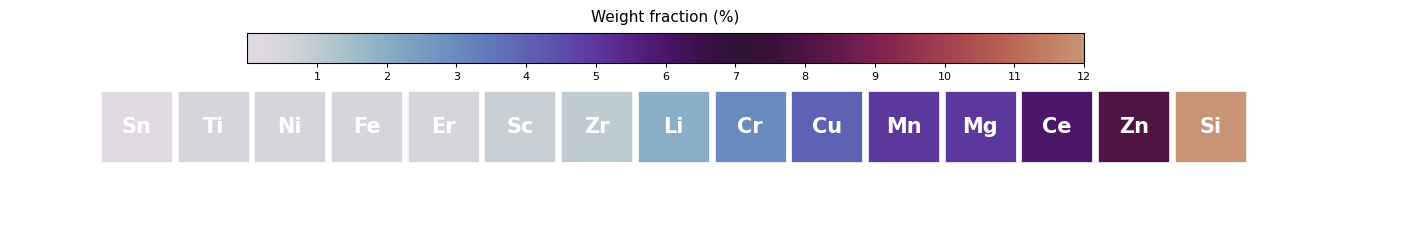

In [ ]:
from pathlib import Path
from typing import Dict

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon, Rectangle
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import numpy as np
import pandas as pd

# ── Periodic table layout: element -> (row, col) 1-indexed ──────────────────
PTABLE_RC = {
    "H":(1,1),"He":(1,18),
    "Li":(2,1),"Be":(2,2),"B":(2,13),"C":(2,14),"N":(2,15),"O":(2,16),"F":(2,17),"Ne":(2,18),
    "Na":(3,1),"Mg":(3,2),"Al":(3,13),"Si":(3,14),"P":(3,15),"S":(3,16),"Cl":(3,17),"Ar":(3,18),
    "K":(4,1),"Ca":(4,2),"Sc":(4,3),"Ti":(4,4),"V":(4,5),"Cr":(4,6),"Mn":(4,7),"Fe":(4,8),
    "Co":(4,9),"Ni":(4,10),"Cu":(4,11),"Zn":(4,12),"Ga":(4,13),"Ge":(4,14),"As":(4,15),
    "Se":(4,16),"Br":(4,17),"Kr":(4,18),
    "Rb":(5,1),"Sr":(5,2),"Y":(5,3),"Zr":(5,4),"Nb":(5,5),"Mo":(5,6),"Tc":(5,7),"Ru":(5,8),
    "Rh":(5,9),"Pd":(5,10),"Ag":(5,11),"Cd":(5,12),"In":(5,13),"Sn":(5,14),"Sb":(5,15),
    "Te":(5,16),"I":(5,17),"Xe":(5,18),
    "Cs":(6,1),"Ba":(6,2),"La":(6,3),"Hf":(6,4),"Ta":(6,5),"W":(6,6),"Re":(6,7),"Os":(6,8),
    "Ir":(6,9),"Pt":(6,10),"Au":(6,11),"Hg":(6,12),"Tl":(6,13),"Pb":(6,14),"Bi":(6,15),
    "Po":(6,16),"At":(6,17),"Rn":(6,18),
    "Fr":(7,1),"Ra":(7,2),"Ac":(7,3),"Rf":(7,4),"Db":(7,5),"Sg":(7,6),"Bh":(7,7),"Hs":(7,8),
    "Mt":(7,9),"Ds":(7,10),"Rg":(7,11),"Cn":(7,12),"Nh":(7,13),"Fl":(7,14),"Mc":(7,15),
    "Lv":(7,16),"Ts":(7,17),"Og":(7,18),
    # Lanthanides row 9
    "Ce":(9,4),"Pr":(9,5),"Nd":(9,6),"Pm":(9,7),"Sm":(9,8),"Eu":(9,9),"Gd":(9,10),
    "Tb":(9,11),"Dy":(9,12),"Ho":(9,13),"Er":(9,14),"Tm":(9,15),"Yb":(9,16),"Lu":(9,17),
    # Actinides row 10
    "Th":(10,4),"Pa":(10,5),"U":(10,6),"Np":(10,7),"Pu":(10,8),"Am":(10,9),"Cm":(10,10),
    "Bk":(10,11),"Cf":(10,12),"Es":(10,13),"Fm":(10,14),"Md":(10,15),"No":(10,16),"Lr":(10,17),
}

HIDDEN_ELEMENTS = {
    "Fr","Ra","Ac","Th","Pa","U","Np","Pu","Am","Cm","Bk","Cf","Es","Fm","Md","No","Lr",
}

# ── Load bounds ──────────────────────────────────────────────────────────────
BOUNDS_PATH = Path("alloy_element_bounds.csv")
bounds_df = pd.read_csv(BOUNDS_PATH)
UPPER_BOUNDS: Dict[str, float] = (
    bounds_df.set_index("Element")["Non-conservative upper (wt%)"].astype(float).to_dict()
)
LOWER_BOUNDS: Dict[str, float] = (
    bounds_df.set_index("Element")["Lower bound (wt%)"].astype(float).to_dict()
)
BOUNDS_ELEMENTS = bounds_df["Element"].tolist()
BOUNDS_ELEMENTS.remove("Al")
indices = np.argsort(bounds_df.iloc[1:]["Recommended upper bound (wt%)"].values)
BOUNDS_ELEMENTS = np.array(list(BOUNDS_ELEMENTS))[indices]

OUT_DIR = Path("figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = OUT_DIR / "periodic_table_bounds3.png"

# ── Colormap + norm ──────────────────────────────────────────────────────────
base_cmap = plt.get_cmap("twilight")
truncated_colors = base_cmap(np.linspace(0.0, 0.85, 256))
truncated_cmap = LinearSegmentedColormap.from_list("magma_trunc", truncated_colors)

eps = 1e-6
all_vals = []
for el in BOUNDS_ELEMENTS:
    if el in PTABLE_RC:
        all_vals += [max(LOWER_BOUNDS[el], eps), max(UPPER_BOUNDS[el], eps)]
log_norm = mcolors.Normalize(vmin=min(all_vals), vmax=12)

def el_color(val):
    return truncated_cmap(log_norm(max(val, eps)))

# ── Draw ─────────────────────────────────────────────────────────────────────
CELL = 1.0          # cell size
GAP  = 0.08         # gap between cells

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_aspect("equal")
ax.axis("off")

N_ROWS, N_COLS = 10, 18

for el, i in zip(BOUNDS_ELEMENTS, np.arange(1, 16)):
    if el == "Al":
        i -= 1
        continue

    x = i * (CELL + GAP)
    # rows 9 and 10 (lanthanides/actinides) get a vertical gap
    y = 1

    in_bounds = el in BOUNDS_ELEMENTS and el != "Al"
    lower_val = max(LOWER_BOUNDS.get(el, eps), eps)
    upper_val = max(UPPER_BOUNDS.get(el, eps), eps)

    if in_bounds:
        lower_color = el_color(lower_val)
        upper_color = el_color(upper_val)
    else:
        lower_color = upper_color = "#808080"

    # Upper-right triangle
    upper_tri = Polygon(
        [(x, y+CELL), (x+CELL, y+CELL), (x+CELL, y), (x, y)],
        closed=True, facecolor=upper_color, edgecolor="white", linewidth=0.5,
    )
    # Lower-left triangle
    lower_tri = Polygon(
        [(x, y+CELL), (x+CELL, y), (x, y)],
        closed=True, facecolor=lower_color, edgecolor="white", linewidth=0.5,
    )
    ax.add_patch(lower_tri)
    ax.add_patch(upper_tri)

    # Element symbol
    txt_color = "#D0D0D0" if not in_bounds else "white"
    if el in BOUNDS_ELEMENTS and el != "Al":
        ax.text(
            x + CELL/2, y + CELL/2, el,
            ha="center", va="center", fontsize=15,
            color=txt_color, fontweight="bold",
        )

ax.set_xlim(-0.2, N_COLS * (CELL + GAP))
ax.set_ylim(0, 2)

# ── Colorbar ─────────────────────────────────────────────────────────────────
tick_values = np.arange(0, 13)

def _tick_label(val):
    if np.isclose(val, eps): return "0"
    return f"{val:.6f}".rstrip("0").rstrip(".")
pos = ax.get_position()

cbar_ax = fig.add_axes([
    pos.x0 + 0.17 * pos.width,   # align horizontally with your boxes
    pos.y0 + 1.2 * pos.height, # vertical position JUST above boxes
    0.6 * pos.width,            # width similar to your row
    0.03                        # height
])
cbar = fig.colorbar(
    ScalarMappable(norm=log_norm, cmap=truncated_cmap),
    cax=cbar_ax, orientation="horizontal", ticks=tick_values,
)
cbar.set_ticklabels([_tick_label(v) for v in tick_values])
cbar.ax.tick_params(which="both", length=3, labelsize=8)
cbar.ax.set_title("Weight fraction (%)", fontsize=11, pad=8)

# ── Legend ───────────────────────────────────────────────────────────────────
# legend_ax = fig.add_axes((0.54, 0.86, 0.10, 0.10))
# legend_ax.set_axis_off()
# legend_ax.set_aspect("equal")
# legend_ax.set_xlim(0, 1)
# legend_ax.set_ylim(0, .5)
# legend_ax.add_patch(Rectangle((0.05,0.25), 0.35, 0.35,
#     facecolor="none", edgecolor="black", linewidth=1.2))
# legend_ax.add_patch(Polygon(
#     [(0.05,0.25),(0.05,0.60),(0.40,0.25)],
#     closed=True, facecolor="#d9d9d9", edgecolor="black", linewidth=1.0))
# legend_ax.add_patch(Polygon(
#     [(0.05,0.60),(0.40,0.25),(0.40,0.60)],
#     closed=True, facecolor="#bdbdbd", edgecolor="black", linewidth=1.0))
# legend_ax.text(0.48, 0.52, "Upper", va="center", fontsize=10)
# legend_ax.text(0.48, 0.30, "Lower", va="center", fontsize=10)

fig.savefig(OUT_PATH, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Saved to {OUT_PATH}")
plt.show()